## 1. Import Neccessary libraries

In [1]:
pip install scikit-learn


[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [41]:
pip install statsmodels

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 3.8 MB/s eta 0:00:00m eta 0:00:010:01:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.3/233.3 kB 12.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 9.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.7/105.7 kB 7.2 MB/s eta 0:00:00

[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [62]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression

import warnings                         ## this will remove warning in output
warnings.filterwarnings(action="ignore")

## 2.Data Collection

Import dataset

In [2]:
cars_data = pd.read_csv("Cars.csv")
cars_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099


## 3.Data Understanding

## 3.1 Preform initial investigation on data

In [3]:
cars_data.shape  # rows called as RECORDS OR OBSERVATION , columns called as featires or parameters
# here we can say as 32 observation with 12 features

(81, 5)

In [4]:
cars_data.isna().sum()  # the data is clean

HP     0
MPG    0
VOL    0
SP     0
WT     0
dtype: int64

In [5]:
cars_data.dtypes

HP       int64
MPG    float64
VOL      int64
SP     float64
WT     float64
dtype: object

In [6]:
cars_data.describe()

,HP,MPG,VOL,SP,WT
count,81.000000,81.000000,81.000000,81.000000,81.000000
mean,117.469136,34.422076,98.765432,121.540272,32.412577
std,57.113502,9.131445,22.301497,14.181432,7.492813
min,49.000000,12.101263,50.000000,99.564907,15.712859
25%,84.000000,27.856252,89.000000,113.829145,29.591768
50%,100.000000,35.152727,101.000000,118.208698,32.734518
75%,140.000000,39.531633,113.000000,126.404312,37.392524
max,322.000000,53.700681,160.000000,169.598513,52.997752


## 3.2 Now lets check for the assumption

## 3.2.1 Linearity Test

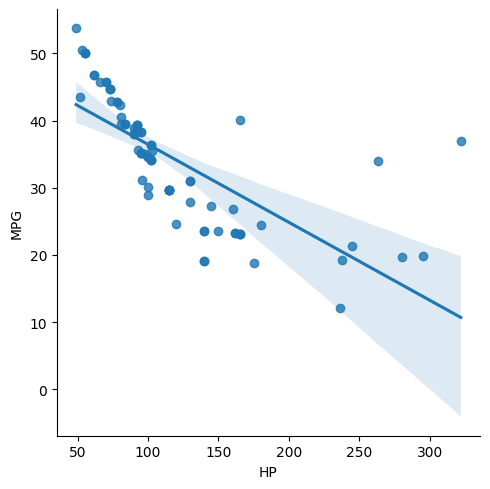

In [8]:
## to check linesrity we can for lmplot

sns.lmplot(data = cars_data ,x="HP",y="MPG")

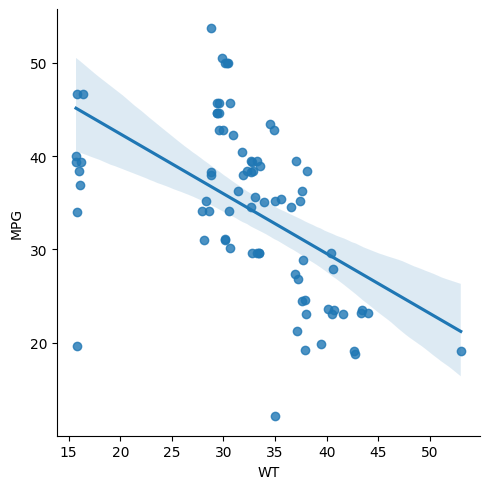

In [9]:
sns.lmplot(data = cars_data ,x="WT",y="MPG")

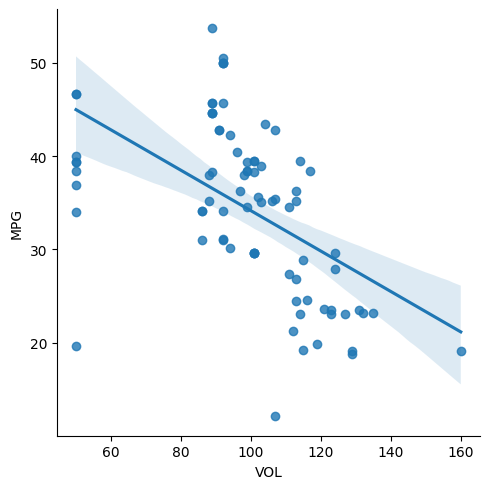

In [10]:
sns.lmplot(data = cars_data ,x="VOL",y="MPG")

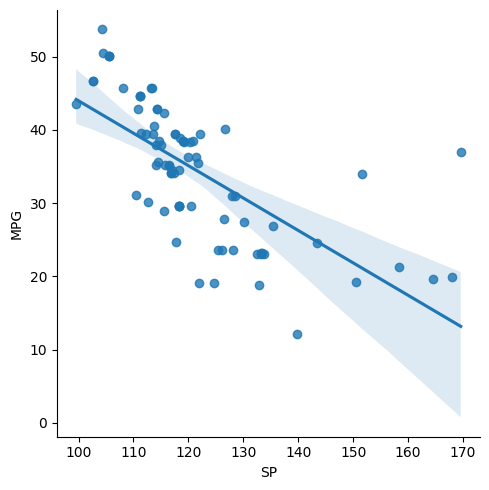

In [11]:
sns.lmplot(data = cars_data ,x="SP",y="MPG")

## Test1 linearity failed. Because the values are more scattered .

## 3.2.2 Normality Test

the Bell curve should be achieved for normality test

(array([15., 35.,  9.,  6.,  9.,  0.,  2.,  2.,  1.,  2.]),
 array([ 49. ,  76.3, 103.6, 130.9, 158.2, 185.5, 212.8, 240.1, 267.4,
        294.7, 322. ]),
 <BarContainer object of 10 artists>)

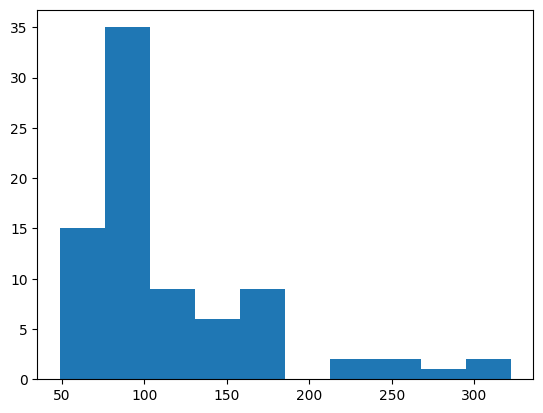

In [12]:
## Test 2
plt.hist(cars_data["HP"])  # here it left skewed

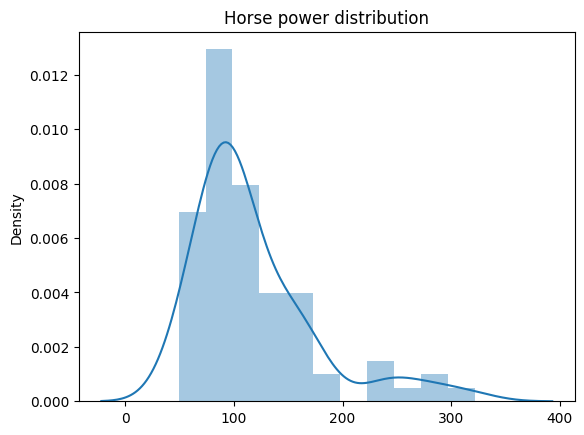

In [13]:
sns.distplot(x=cars_data["HP"])
plt.title("Horse power distribution")
plt.show()

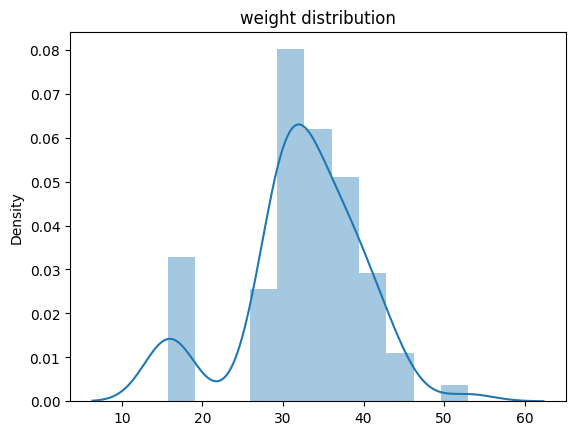

In [14]:
sns.distplot(x=cars_data["WT"])
plt.title("weight distribution")
plt.show()

## Test2 Normality Test is failed . Because the datapoints are either left or right skewed curved.

In [15]:
cars_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099


## 3.3.3 Test 3 - Multicollinearity test

**There should not be very highly correlated between the input(X) observation**

### correlation values

0.0 - zero correlation

0.0 - 2.0 -> very weak correlation

0.21 - 0.40 -> weak

0.41 - 0.60 -> moderate 

0.61 - 0.80 -> strong

0.81 - 1.0 ->very strong

1.00 -> highly correlated

In [16]:
cars_matrix = cars_data.corr()
cars_matrix

,HP,MPG,VOL,SP,WT
HP,1.000000,-0.725038,0.077459,0.973848,0.076513
MPG,-0.725038,1.000000,-0.529057,-0.687125,-0.526759
VOL,0.077459,-0.529057,1.000000,0.102170,0.999203
SP,0.973848,-0.687125,0.102170,1.000000,0.102439
WT,0.076513,-0.526759,0.999203,0.102439,1.000000


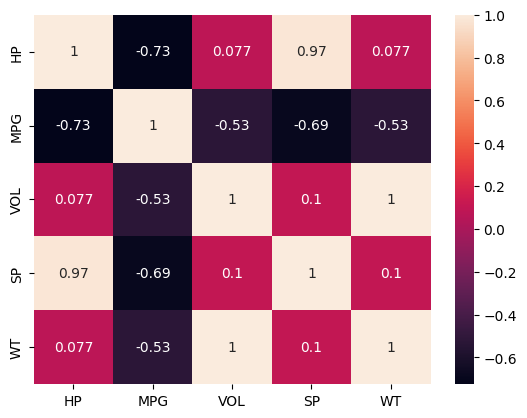

In [17]:
sns.heatmap(data = cars_matrix,annot=True)
plt.show()

## Test3 - There is Multicollinearity in the data

## 3.3.4 Test 4 - Auto Regression

**Input columns (x) should not be time based such as date,time,weather . So in our dataset we are not having time based columns**

## Test4 Auto Regression is passed

## Test5 - Homoscadacity and Test6 - Zero Residual mean - will be done after Model is built ,trained and tested

## 4. Data preparation

**all the features should be numeric**

## 4.1 Data cleaning - Here the data is already cleaned - no null values

In [18]:
cars_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099


## 4.2 Seperating X and Y values

In [19]:
# need to set input X

X = cars_data[["HP","VOL","SP","WT"]]
X

,HP,VOL,SP,WT
0,49,89,104.185353,28.762059
1,55,92,105.461264,30.466833
2,55,92,105.461264,30.193597
3,70,92,113.461264,30.632114
4,53,92,104.461264,29.889149
...,...,...,...,...
76,322,50,169.598513,16.132947
77,238,115,150.576579,37.923113
78,263,50,151.598513,15.769625
79,295,119,167.944460,39.423099


In [20]:
# need to set output y

y = cars_data[["MPG"]]
y

,MPG
0,53.700681
1,50.013401
2,50.013401
3,45.696322
4,50.504232
...,...
76,36.900000
77,19.197888
78,34.000000
79,19.833733


## There is nothing to prepare because all the features are in numeric. And we can do Feature engineering

## 5. Model Building

In [21]:
linear_model = LinearRegression()   # calling the model

## 6. Model Training

** we have four inputs so y = m1x1 + m2x2 + m3x3 + m4x4 + c **


In [22]:
linear_model.fit(X,y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [23]:
linear_model.intercept_    # c value

array([30.67733585])

In [24]:
linear_model.coef_       # m1,m2,m3,m4 value

array([[-0.20544372, -0.33605084,  0.39562692,  0.40057409]])

## 7. Model Testing

In [25]:
y_pred = linear_model.predict(X)
y_pred

array([[43.44193477],
       [42.38879289],
       [42.27934147],
       [42.53835981],
       [42.17264802],
       [43.02061916],
       [42.32536062],
       [48.07621852],
       [48.28120247],
       [40.79122814],
       [41.52153227],
       [47.80956747],
       [39.95980269],
       [41.52757889],
       [41.76632332],
       [41.6181448 ],
       [41.15094046],
       [47.98605515],
       [41.30861046],
       [37.87127922],
       [38.57706414],
       [37.35199705],
       [37.89770285],
       [39.5625144 ],
       [39.93380662],
       [46.73870908],
       [35.48165898],
       [38.78152504],
       [38.24861192],
       [36.00285298],
       [34.84603989],
       [37.21630246],
       [37.13919796],
       [34.82541399],
       [37.22361389],
       [37.53950097],
       [39.27144845],
       [38.24219888],
       [38.54286458],
       [35.9391722 ],
       [34.2129755 ],
       [35.36313259],
       [37.50473376],
       [38.07998482],
       [35.79651664],
       [36

## 8. Model Evaluation

In [30]:
error = y - y_pred
error

,MPG
0,10.258747
1,7.624608
2,7.734060
3,3.157963
4,8.331584
...,...
76,15.617904
77,1.298838
78,7.863547
79,7.517122


In [27]:
error.mean()

MPG   -3.311480e-15
dtype: float64

In [37]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score

In [29]:
mean_absolute_error(y,y_pred)   # y-orginal output , y_pred - testing output

3.2679682854207983

In [33]:
mean_squared_error(y,y_pred)

18.897141152343103

In [36]:
root_mean_squared_error(y,y_pred) # normalising the units

4.347084212704316

In [38]:
r2_score(y,y_pred)  

0.7705372737359844

In [42]:
import statsmodels.formula.api as smf 

In [43]:
cars_data.head()

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149


In [45]:
linear_stats_model = smf.ols(formula = "MPG ~ HP+VOL+SP+WT" , data = cars_data).fit()

In [47]:
print("R2 score : " ,linear_stats_model.rsquared.round(2), "\nAdjusted R2 score:" ,linear_stats_model.rsquared_adj.round(2))

R2 score :  0.77 
Adjusted R2 score: 0.76


## To see Adjusted R2 score , we are using OLS technique from Statsmodel Formula

In [48]:
linear_stats_model = smf.ols(formula = "MPG ~ HP" , data = cars_data).fit()

In [49]:
print("R2 score : " ,linear_stats_model.rsquared.round(2), "\nAdjusted R2 score:" ,linear_stats_model.rsquared_adj.round(2))

R2 score :  0.53 
Adjusted R2 score: 0.52


In [52]:
linear_stats_model = smf.ols(formula = "MPG ~ HP+VOL" , data = cars_data).fit()

In [54]:
print("R2 score : " ,linear_stats_model.rsquared.round(2), "\nAdjusted R2 score:" ,linear_stats_model.rsquared_adj.round(2))

R2 score :  0.75 
Adjusted R2 score: 0.74


In [ ]:
linear_stats_model = smf.ols(formula = "MPG ~ HP+VOL+SP" , data = cars_data).fit()

In [55]:
print("R2 score : " ,linear_stats_model.rsquared.round(2), "\nAdjusted R2 score:" ,linear_stats_model.rsquared_adj.round(2))

R2 score :  0.75 
Adjusted R2 score: 0.74


## Training and Testing and evaluation

In [57]:
from sklearn.model_selection import train_test_split

In [58]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size= 0.20,shuffle=True,random_state=32)

## X_train,y_train - training data
## X_test,y_test - testing data

## Spliting the data

In [60]:
X_train,y_train

(     HP  VOL          SP         WT
 45  100   99  117.105055  32.621916
 14   66   89  108.185353  29.347279
 23   81   96  113.829145  31.837122
 25   92   50  114.598513  16.043175
 69  245  112  158.300669  37.141733
 ..  ...  ...         ...        ...
 19   90  103  118.472936  33.516974
 62  140  131  126.048103  43.390988
 54  160  113  135.392639  37.254392
 5    70   89  113.185353  29.591768
 43   95   88  114.093383  28.343976
 
 [64 rows x 4 columns],
           MPG
 45  34.561499
 14  45.734893
 23  40.474723
 25  38.411003
 69  21.273708
 ..        ...
 19  38.901834
 62  23.515917
 54  26.852279
 5   45.696322
 43  35.152727
 
 [64 rows x 1 columns])

In [61]:
X_test,y_test

(     HP  VOL          SP         WT
 21   74  107  110.840817  34.908211
 49  115  101  118.288996  33.458472
 8    62   50  102.598513  16.359484
 12   92   99  122.105055  32.813592
 28   52  104   99.564907  34.483207
 33  102  113  121.392639  37.573290
 7    62   50  102.598513  15.847758
 1    55   92  105.461264  30.466833
 58  100   94  112.645204  30.615283
 48  130   86  127.909442  28.070597
 60  145  111  130.208698  36.888153
 70  280   50  164.598513  15.823060
 56   96   92  110.461264  30.147543
 15   73   89  111.185353  29.604527
 22   95  101  120.288996  32.675828
 55  130  124  126.404312  40.589068
 39  130   92  128.461264  30.115434,
           MPG
 21  42.828479
 49  29.629936
 8   46.716554
 12  39.354094
 28  43.469434
 33  36.285456
 7   46.716554
 1   50.013401
 58  30.131923
 48  31.014131
 60  27.354265
 70  19.678507
 56  31.113584
 15  44.652834
 22  38.310606
 55  27.856252
 39  31.014131)

## calling the model

In [63]:
linear_model = LinearRegression()

In [64]:
linear_model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [66]:
## predicitng output of training data

y_pred_train = linear_model.predict(X_train)
y_pred_train

array([[36.03349187],
       [41.12559158],
       [39.04207624],
       [47.85147866],
       [22.33069231],
       [38.73436173],
       [36.65226465],
       [25.85089994],
       [33.50397491],
       [15.97367055],
       [49.33713444],
       [38.13891307],
       [17.18786626],
       [41.61801   ],
       [41.39409211],
       [24.76742351],
       [19.25035232],
       [34.03491922],
       [25.85339694],
       [24.29039634],
       [25.45956959],
       [38.82727365],
       [25.35945716],
       [41.78534898],
       [36.00204172],
       [34.77312721],
       [23.43290405],
       [34.87657343],
       [41.50381383],
       [28.63671811],
       [43.39872972],
       [35.28170756],
       [29.29667161],
       [32.66118036],
       [35.85776172],
       [36.32028984],
       [29.3457398 ],
       [20.5794244 ],
       [41.13582346],
       [38.08117407],
       [31.86024078],
       [14.66285604],
       [33.35917528],
       [28.35322405],
       [39.36529704],
       [32

In [ ]:
## predicitng output of testing data

In [69]:
y_pred_test = linear_model.predict(X_test)
y_pred_test

array([[37.10328425],
       [32.6395501 ],
       [47.82782017],
       [40.39141028],
       [36.07571914],
       [34.45595991],
       [48.33648626],
       [41.34640714],
       [35.07429786],
       [38.25731081],
       [29.9401738 ],
       [32.5083074 ],
       [35.05075736],
       [40.91108486],
       [39.06368747],
       [28.96152853],
       [37.15217434]])

## Model evaluation 

In [70]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score

In [71]:
mean_absolute_error(y_train,y_pred_train)

3.109142723497615

In [72]:
mean_absolute_error(y_test,y_pred_test)

4.3335363156094395

In [74]:
mean_squared_error(y_train,y_pred_train)

17.75375609207913

In [75]:
mean_squared_error(y_test,y_pred_test)

29.238201156244454

In [76]:
root_mean_squared_error(y_train,y_pred_train)

4.21352062912704

In [77]:
root_mean_squared_error(y_test,y_pred_test)

5.40723599968084

In [78]:
r2_score(y_train,y_pred_train)

0.7905236323200333

In [79]:
r2_score(y_test,y_pred_test)

0.5770101929490705

## To fit the training data in stats model we need to add constant in X_train,X_test

In [87]:
import statsmodels.formula.api as smf
import statsmodels.api as sm

In [88]:
X_train = sm.add_constant(X_train)
X_test = sm.add_constant(X_test)

In [93]:
linear_statsmodel = sm.OLS(y_train,X_train).fit()

In [94]:
print("\nadjusted r2 square:",linear_statsmodel.rsquared_adj.round(2))


adjusted r2 square: 0.78


In [95]:
linear_statsmodel_test = sm.OLS(y_test,X_test).fit()

In [96]:
print("\nadjusted r2 square:",linear_statsmodel_test.rsquared_adj.round(2))


adjusted r2 square: 0.84


In [ ]:
#cars_data["error"] = error

In [ ]:
#cars_data

## lets perform  Test 5 : Homoscedasticity Test from the assumptions

**The assumptions that the variance of the errors remain constant accross all the independent variables in a regression model.(i.e : above the  zero and below the zero the error should be equal)**

In [ ]:
sns.scatterplot(data=cars_data,x="HP", y=error)
plt.show()

In [ ]:
sns.scatterplot(data=cars_data,x="wt", y=error)
plt.show()

## Test 5 : Homoscedasticity Test  is failed

## lets perform  Test 6 : Zero residual mean Test from the assumptions

**The acutal output mpg should be x-axis and predicted output y_pred should be y-axis)**

In [ ]:
sns.scatterplot(x = cars_data["mpg"], y = y_pred)   
plt.show()

## Test 6 : Zero residual mean Test also failed

## 9. Model Deployment

In [53]:
from pickle import dump  # creating this file to load in UI 

In [ ]:
dump(obj = linear_model,file= open(file = "linear_intelligence_file.pkl",model='wb')
         

In [54]:
from pickle import load

In [ ]:
linear_intel_pkl = load(file  = open(file = "linear_intelligence_file.pkl",model='rb'))  # this is to load into UI
linear_intel_pkl

In [ ]:
linear_intel_pkl.predict(X)

******************* The END ************************